08 : Develop a Gradient Boosting regression model to predict wine quality based on physicochemical properties.
Handle missing values, perform feature scaling, and evaluate the model using MSE, MAE, RMSE, and Rsquared. Dataset: Wine Quality Dataset (UCI).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer

In [5]:
df = pd.read_csv('winequality.csv')
print("Dataset Shape :", df.shape)
df.head()

Dataset Shape : (6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [7]:
if df.isnull().sum().sum() > 0:
    print("Missing Values Present !!")
    print(df.isnull().sum())
else :
    print("No Missing Values Found")

Missing Values Present !!
type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64


In [8]:
df.columns

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='object')

In [9]:
x = df.drop(['type', 'quality'], axis=1)
y = df['quality']

In [10]:
imputer = SimpleImputer(strategy='mean')
x = pd.DataFrame(
    imputer.fit_transform(x),
    columns=x.columns
)

In [11]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y , test_size=0.2, random_state=42
)

In [12]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [15]:
model = GradientBoostingRegressor(
    n_estimators=100, 
    max_depth=10,
    random_state=42, 
    learning_rate=0.1
)

In [16]:
model.fit(x_train, y_train)
print("Model Training Completed !!")

Model Training Completed !!


In [17]:
y_pred = model.predict(x_test)
print(y_pred)

[6.88593043 5.96227701 6.84986417 ... 5.34487304 5.77380429 6.02720614]


In [20]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation:")
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("Root Mean Squared Error (RMSE):", rmse)
print("R-squared (R2):", r2)


Model Evaluation:
Mean Squared Error (MSE): 0.34325150139255617
Mean Absolute Error (MAE): 0.4023927482315079
Root Mean Squared Error (RMSE): 0.5858766946999652
R-squared (R2): 0.5197932491066556


In [21]:
result = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Predicted Quality": np.round(y_pred, 2)
})

print("\nActual vs Predicted:")
print(result.head(10))


Actual vs Predicted:
   Actual Quality  Predicted Quality
0               7               6.89
1               7               5.96
2               6               6.85
3               6               6.00
4               5               5.04
5               7               6.83
6               6               5.84
7               5               5.61
8               5               5.32
9               6               5.78


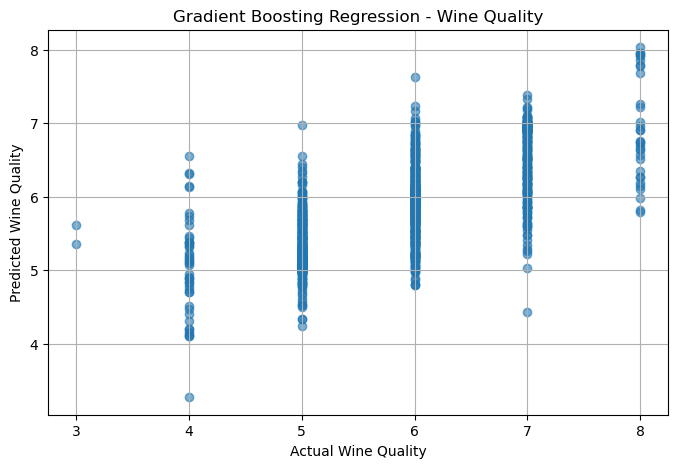

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")
plt.title("Gradient Boosting Regression - Wine Quality")
plt.grid(True)
plt.show()

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [10]:
df = pd.read_csv('winequality.csv')
print("Dataset Shape :", df.shape)
df.head()

Dataset Shape : (6497, 13)


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [11]:
if df.isnull().sum().sum() > 0:
    print("Missing Values Present !!")
    print(df.isnull().sum())
else :
    print("No Missing Values Found")

Missing Values Present !!
type                     0
fixed acidity           10
volatile acidity         8
citric acid              3
residual sugar           2
chlorides                2
free sulfur dioxide      0
total sulfur dioxide     0
density                  0
pH                       9
sulphates                4
alcohol                  0
quality                  0
dtype: int64


In [12]:
df.columns

Index(['type', 'fixed acidity', 'volatile acidity', 'citric acid',
       'residual sugar', 'chlorides', 'free sulfur dioxide',
       'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol',
       'quality'],
      dtype='object')

In [13]:
x = df.drop(['type', 'quality'], axis=1)
y = df['quality']

In [14]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [15]:
base_model = Pipeline([
    ("imputer", SimpleImputer(strategy='mean')),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

base_model.fit(x_train, y_train)
print("Model Training Completed !!")
base_pred = base_model.predict(x_test)
print(base_pred)

Model Training Completed !!
[6.35180223 5.99746002 5.75455719 ... 5.57578536 5.67081248 5.4337994 ]


In [16]:
base_mse = mean_squared_error(y_test, base_pred)
base_mae = mean_absolute_error(y_test, base_pred)
base_rmse = np.sqrt(base_mse)
base_r2 = r2_score(y_test, base_pred)

print("Base Model : Linear_Regression")
print("MSE :", base_mse)
print("MAE :", base_mae)
print("RMSE :", base_rmse)
print("R2 :", base_r2)

Base Model : Linear_Regression
MSE : 0.47617961982563195
MAE : 0.5463861742355259
RMSE : 0.6900576931138671
R2 : 0.3338276244957058


In [17]:
gb_model = Pipeline([
    ("imputer", SimpleImputer(strategy='mean')),
    ("scaler", StandardScaler()),
    ("regressor", GradientBoostingRegressor(
        learning_rate=0.1,
        n_estimators=100,
        random_state=42,
        max_depth=10
    ))
])

gb_model.fit(x_train, y_train)
print("Model Training Completed !!")
gb_pred = gb_model.predict(x_test)
print(gb_pred)

Model Training Completed !!
[6.91240032 6.08557565 6.85763207 ... 5.40903617 5.75114828 5.9974623 ]


In [18]:
gb_mse = mean_squared_error(y_test, gb_pred)
gb_mae = mean_absolute_error(y_test, gb_pred)
gb_rmse = np.sqrt(base_mse)
gb_r2 = r2_score(y_test, gb_pred)

print("Model : Gradient_Boosting")
print("MSE :", gb_mse)
print("MAE :", gb_mae)
print("RMSE :", gb_rmse)
print("R2 :", gb_r2)

Model : Gradient_Boosting
MSE : 0.3352123724332433
MAE : 0.39724460044025767
RMSE : 0.6900576931138671
R2 : 0.5310399413480662


In [23]:
mse_improvement = (((base_mse) - (gb_mse)) / (base_mse)) * 100
mae_improvement = (((base_mae) - (gb_mae)) / (base_mae)) * 100
rmse_improvement = (((base_rmse) - (gb_rmse)) / (base_rmse)) * 100
r2_improvement = abs((gb_r2) - (base_r2) / (base_r2)) * 100

print("***IMPROVEMENT AFTER GRADIENT BOOSTING***")
print("MSE Improvement :", round(mse_improvement, 2), "%")
print("MAE Improvement :", round(mae_improvement, 2), "%")
print("RMSE Improvement :", round(rmse_improvement, 2), "%")
print("R2 Improvement :", round(r2_improvement, 2), "%")

***IMPROVEMENT AFTER GRADIENT BOOSTING***
MSE Improvement : 29.6 %
MAE Improvement : 27.3 %
RMSE Improvement : 0.0 %
R2 Improvement : 46.9 %


In [24]:
results = pd.DataFrame({
    "Metric": ["MSE", "MAE", "RMSE", "R2"],
    "Linear Regression": [
        base_mse,
        base_mae,
        base_rmse,
        base_r2
    ],
    "Gradient Boosting": [
        gb_mse,
        gb_mae,
        gb_rmse,
        gb_r2
    ]
})
print("MODEL COMPARISON")
print(results.to_string(index=False))

MODEL COMPARISON
Metric  Linear Regression  Gradient Boosting
   MSE           0.476180           0.335212
   MAE           0.546386           0.397245
  RMSE           0.690058           0.690058
    R2           0.333828           0.531040


In [25]:
comparison = pd.DataFrame({
    "Actual Quality": y_test.values,
    "Predicted Quality": gb_pred
})
print("ACTUAL VS PREDICTED VALUES")
print(comparison.head(10))

ACTUAL VS PREDICTED VALUES
   Actual Quality  Predicted Quality
0               7           6.912400
1               7           6.085576
2               6           6.857632
3               6           6.008087
4               5           5.037628
5               7           7.021710
6               6           5.905604
7               5           5.408620
8               5           5.169536
9               6           5.670136


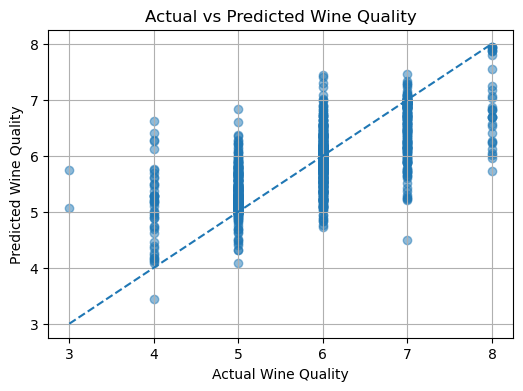

In [26]:
# PLOT ACTUAL VS PREDICTED VALUES
plt.figure(figsize=(6, 4))
plt.scatter(
y_test,
gb_pred,
alpha=0.5
)
# Perfect prediction line
plt.plot(
[y_test.min(), y_test.max()],
[y_test.min(), y_test.max()],
linestyle="--"
)
plt.xlabel("Actual Wine Quality")
plt.ylabel("Predicted Wine Quality")
plt.title("Actual vs Predicted Wine Quality")
plt.grid(True)
plt.show()